# Final Comparison — all four C-MAPSS datasets
**Notebook:** `14_Final_Comparison.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

This notebook **trains nothing and evaluates nothing new**. It only reads the saved results of the four dataset pipelines (Phases 2–6 for FD001–FD004) and puts them side by side:
1. Data characteristics and the decisions each pipeline made (scaling, sensors, cap, window, LSTM input).
2. Validation comparison (the basis of every model selection).
3. Official test results (selected model ★ plus the reference models).
4. A machine-readable summary (`reports/final_comparison/summary.json`) for the dashboard's Model Comparison page.

The four datasets were **processed separately and never combined**, as the project requires.

⚙️ CPU, under 1 minute.

## Cell 1 — Setup and checks

In [1]:
# Cell 1 — Setup
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])
OUT = PROJECT_DIR / "reports" / "final_comparison"; OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
DATASETS, MODELS = ["FD001", "FD002", "FD003", "FD004"], ["Linear Regression", "Random Forest", "XGBoost", "LSTM"]
missing = [fd for fd in DATASETS if not (PROJECT_DIR / "reports" / "model_results" / fd / "test_evaluation.json").exists()]
assert not missing, f"Finish the evaluation notebook(s) for {missing} first"
print("✅ All four datasets have been evaluated")

✅ All four datasets have been evaluated


## Cell 2 — Datasets and pipeline decisions

In [2]:
# Cell 2 — One row per dataset
DESC = {"FD001": (1, 1), "FD002": (6, 1), "FD003": (1, 2), "FD004": (6, 2)}
rows = []
for fd in DATASETS:
    m = PROJECT_DIR / "models" / fd
    pm = json.loads((m / "preprocessing" / "pipeline_metadata.json").read_text())
    fc = json.loads((m / "feature_config.json").read_text())
    sel = json.loads((m / "selected_model.json").read_text())
    split = json.loads((PROJECT_DIR / "data" / "processed" / fd / "split.json").read_text())
    n_tr, n_va = len(split["train_engine_ids"]), len(split["val_engine_ids"])
    rows.append({"Dataset": fd, "Conditions": DESC[fd][0], "Fault modes": DESC[fd][1],
                 "Train/val engines": f"{n_tr}/{n_va}",
                 "Scaling": "per-regime" if pm.get("kind") == "regime" else "global",
                 "Sensors": len(pm["feature_cols"]), "RUL cap": pm["rul_cap"],
                 "Tabular window": fc["tabular"]["window"], "Tabular features": fc["tabular"]["n_features"],
                 "LSTM input": f'{fc["lstm"]["seq_len"]}×{fc["lstm"]["n_features"]}'
                               + (" (+means)" if fc["lstm"].get("rolling_window") else ""),
                 "Selected model": sel["selected_model"]})
setup = pd.DataFrame(rows).set_index("Dataset")
setup.to_csv(OUT / "pipeline_decisions.csv"); display(setup)

,Conditions,Fault modes,Train/val engines,Scaling,Sensors,RUL cap,Tabular window,Tabular features,LSTM input,Selected model
Dataset,,,,,,,,,,
FD001,1,1,80/20,global,14,125,30,57,30×14,XGBoost
FD002,6,1,208/52,per-regime,14,125,200,57,21×28 (+means),Random Forest
FD003,1,2,80/20,global,14,125,30,57,30×28 (+means),Random Forest
FD004,6,2,199/50,per-regime,14,100,200,57,19×28 (+means),Random Forest


**How to read it:** the harder the dataset (more operating conditions and fault modes), the more the pipeline had to adapt: per-regime scaling for 6 conditions, and longer history windows when the signal is noisier. Each choice was made on that dataset's own validation engines.

## Cell 3 — Validation comparison (basis of selection)

In [3]:
# Cell 3 — Validation RMSE / NASA (true RUL ≤ cap) from each Phase 6 run
pick = lambda df, prefix: df[[c for c in df.columns if c.startswith(prefix)][0]]
val_rows = []
for fd in DATASETS:
    v = pd.read_csv(PROJECT_DIR / "reports" / "model_results" / fd / "validation_comparison_cpu.csv", index_col="Model")
    for model in MODELS:
        val_rows.append({"Dataset": fd, "Model": model, "Val RMSE (≤cap)": pick(v, "RMSE (≤").loc[model],
                         "Val MAE (≤cap)": pick(v, "MAE (≤").loc[model], "Val NASA (≤cap)": pick(v, "NASA (≤").loc[model],
                         "Val bias (≤cap)": pick(v, "Bias (≤").loc[model], "Model size (MB)": v.loc[model, "Model size (MB)"],
                         "CPU inference (ms)": v[[c for c in v.columns if c.startswith("CPU inference")][0]].loc[model]})
val = pd.DataFrame(val_rows)
val_pivot = val.pivot(index="Model", columns="Dataset", values="Val RMSE (≤cap)").loc[MODELS]
display(val_pivot.round(2))

Dataset,FD001,FD002,FD003,FD004
Model,,,,
Linear Regression,20.26,20.30,19.37,16.08
Random Forest,13.99,10.86,12.52,10.43
XGBoost,13.67,11.25,12.85,10.27
LSTM,15.95,17.26,13.17,15.15


## Cell 4 — Official test results
Each dataset's test set was evaluated **once**, after its model was frozen. ★ = selected model. Two RMSE views:
- **RMSE (all engines):** against the true, uncapped RUL. Engines with true RUL above the cap are necessarily under-predicted (the accepted "≥ cap = healthy" trade-off).
- **RMSE (true ≤ cap):** the region where predictions drive maintenance decisions.
- **RMSE (true ≤ 100, common):** the caps differ (FD004 chose 100 by its rule), so "≤ cap" isn't the same yardstick everywhere. True RUL ≤ 100 is covered by every cap, so use this column to compare datasets.

In [4]:
# Cell 4 — Test table
test_rows = []
for fd in DATASETS:
    t = pd.read_csv(PROJECT_DIR / "reports" / "model_results" / fd / "test_results.csv", index_col="Model")
    sel = json.loads((PROJECT_DIR / "models" / fd / "selected_model.json").read_text())["selected_model"]
    tp = pd.read_csv(PROJECT_DIR / "reports" / "model_results" / fd / "test_predictions.csv")
    common = tp.true_rul <= 100            # same yardstick for every dataset (caps differ: 125 or 100)
    for model in MODELS:
        test_rows.append({"Dataset": fd, "Model": model, "Selected": "★" if model == sel else "",
                          "Test engines": int(len(tp)),
                          "Test RMSE (true ≤100, common)": float(np.sqrt(np.mean((tp.loc[common, model] - tp.loc[common, "true_rul"]) ** 2))),
                          "Test MAE": t.loc[model, "MAE"], "Test RMSE": t.loc[model, "RMSE"],
                          "Test RMSE (true ≤cap)": pick(t, "RMSE (true ≤").loc[model],
                          "Test NASA": t.loc[model, "NASA score"], "Test bias": t.loc[model, "Bias"],
                          "Late > 10 (%)": t.loc[model, "Late > 10 cycles (%)"]})
test = pd.DataFrame(test_rows)
full = val.merge(test, on=["Dataset", "Model"])
full.to_csv(OUT / "all_models_all_datasets.csv", index=False)
selected = full[full.Selected == "★"].set_index("Dataset")
display(selected[["Model", "Val RMSE (≤cap)", "Test RMSE (true ≤cap)", "Test RMSE (true ≤100, common)", "Test RMSE",
                  "Test MAE", "Test NASA", "Test bias", "Late > 10 (%)", "Test engines"]].round(2))
print("Test RMSE on true RUL ≤ 100 (same yardstick for all datasets):")
display(test.pivot(index="Model", columns="Dataset", values="Test RMSE (true ≤100, common)").loc[MODELS].round(2))

,Model,Val RMSE (≤cap),Test RMSE (true ≤cap),"Test RMSE (true ≤100, common)",Test RMSE,Test MAE,Test NASA,Test bias,Late > 10 (%),Test engines
Dataset,,,,,,,,,,
FD001,XGBoost,13.67,12.48,12.02,14.22,10.62,282.62,0.17,24.00,100
FD002,Random Forest,10.86,11.37,10.75,23.19,14.74,3884.80,-7.31,12.74,259
FD003,Random Forest,12.52,13.79,14.19,15.46,11.18,515.33,1.45,21.00,100
FD004,Random Forest,10.43,8.95,8.95,33.51,21.84,16165.82,-16.59,8.47,248


Test RMSE on true RUL ≤ 100 (same yardstick for all datasets):


Dataset,FD001,FD002,FD003,FD004
Model,,,,
Linear Regression,17.47,18.19,18.43,16.24
Random Forest,11.48,10.75,14.19,8.95
XGBoost,12.02,10.12,12.29,8.83
LSTM,15.09,14.81,12.30,12.68


## Cell 5 — Charts

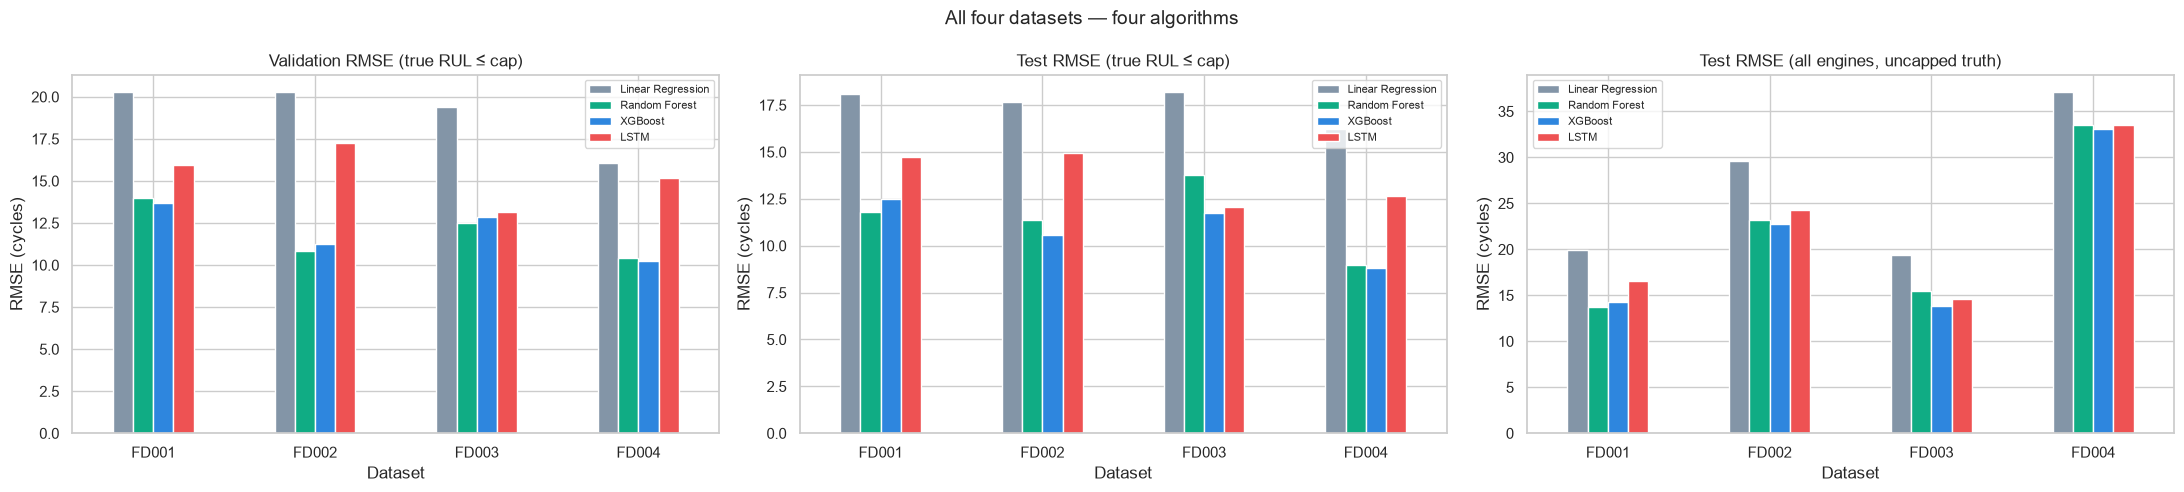

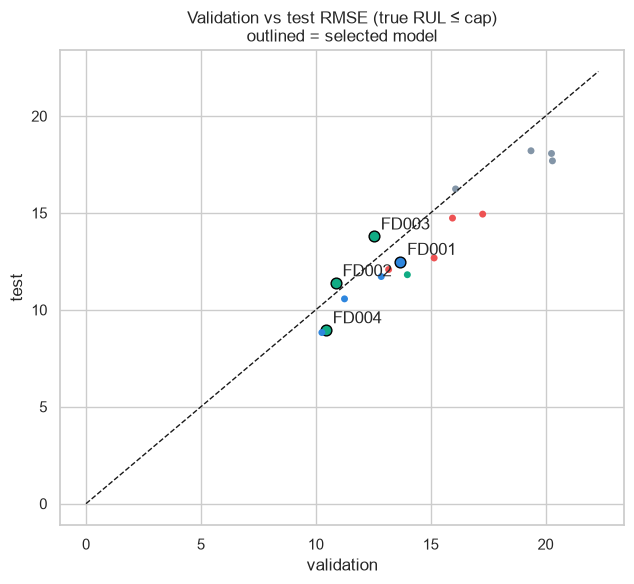

In [5]:
# Cell 5 — Grouped bars + validation-vs-test check
colors = {"Linear Regression": "#8395a7", "Random Forest": "#10ac84", "XGBoost": "#2e86de", "LSTM": "#ee5253"}
fig, axes = plt.subplots(1, 3, figsize=(22, 5))
for ax, (col, title) in zip(axes, [("Val RMSE (≤cap)", "Validation RMSE (true RUL ≤ cap)"),
                                   ("Test RMSE (true ≤cap)", "Test RMSE (true RUL ≤ cap)"),
                                   ("Test RMSE", "Test RMSE (all engines, uncapped truth)")]):
    full.pivot(index="Dataset", columns="Model", values=col)[MODELS].plot.bar(ax=ax, rot=0, color=[colors[m] for m in MODELS])
    ax.set(title=title, ylabel="RMSE (cycles)"); ax.legend(fontsize=8)
fig.suptitle("All four datasets — four algorithms", fontsize=14)
fig.tight_layout(); fig.savefig(OUT / "rmse_by_dataset_and_model.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6))
for _, r in full.iterrows():
    ax.scatter(r["Val RMSE (≤cap)"], r["Test RMSE (true ≤cap)"], color=colors[r.Model], s=60 if r.Selected else 25,
               edgecolor="black" if r.Selected else "none")
    if r.Selected:
        ax.annotate(r.Dataset, (r["Val RMSE (≤cap)"], r["Test RMSE (true ≤cap)"]), xytext=(5, 5), textcoords="offset points")
lim = max(full["Val RMSE (≤cap)"].max(), full["Test RMSE (true ≤cap)"].max()) + 2
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set(title="Validation vs test RMSE (true RUL ≤ cap)\noutlined = selected model", xlabel="validation", ylabel="test")
fig.tight_layout(); fig.savefig(OUT / "validation_vs_test.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the validation-vs-test plot:** points near the dashed line mean the validation protocol predicted test performance honestly. Points far **above** it would mean validation was optimistic. That's exactly what freezing the selection before opening the test set protects against.

## Cell 6 — Summary for the dashboard / report

In [6]:
# Cell 6 — summary.json
summary = {"datasets": {}, "note": "Test sets evaluated once per dataset after freezing the selection; truth = uncapped RUL."}
for fd in DATASETS:
    s = selected.loc[fd]
    summary["datasets"][fd] = {
        **{k: (v.item() if hasattr(v, "item") else v) for k, v in setup.loc[fd].items()},
        "selected_model": s["Model"],
        "validation_rmse_le_cap": round(float(s["Val RMSE (≤cap)"]), 2),
        "test_rmse_le_cap": round(float(s["Test RMSE (true ≤cap)"]), 2),
        "test_rmse_le100_common": round(float(s["Test RMSE (true ≤100, common)"]), 2),
        "test_rmse_all": round(float(s["Test RMSE"]), 2), "test_mae": round(float(s["Test MAE"]), 2),
        "test_nasa": round(float(s["Test NASA"]), 1), "test_bias": round(float(s["Test bias"]), 2),
        "all_models_test_rmse_le_cap": {m: round(float(x), 2) for m, x in
                                        test[test.Dataset == fd].set_index("Model")["Test RMSE (true ≤cap)"].items()}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({fd: {k: v for k, v in d.items() if k in ("selected_model", "validation_rmse_le_cap", "test_rmse_le_cap", "test_rmse_all")}
                  for fd, d in summary["datasets"].items()}, indent=1))
print("Saved →", sorted(p.name for p in OUT.iterdir()))

{
 "FD001": {
  "selected_model": "XGBoost",
  "validation_rmse_le_cap": 13.67,
  "test_rmse_le_cap": 12.48,
  "test_rmse_all": 14.22
 },
 "FD002": {
  "selected_model": "Random Forest",
  "validation_rmse_le_cap": 10.86,
  "test_rmse_le_cap": 11.37,
  "test_rmse_all": 23.19
 },
 "FD003": {
  "selected_model": "Random Forest",
  "validation_rmse_le_cap": 12.52,
  "test_rmse_le_cap": 13.79,
  "test_rmse_all": 15.46
 },
 "FD004": {
  "selected_model": "Random Forest",
  "validation_rmse_le_cap": 10.43,
  "test_rmse_le_cap": 8.95,
  "test_rmse_all": 33.51
 }
}
Saved → ['all_models_all_datasets.csv', 'pipeline_decisions.csv', 'rmse_by_dataset_and_model.png', 'summary.json', 'validation_vs_test.png']


## Reference results (full local run)

| Dataset | Selected | Cap | Val RMSE (≤cap) | Test RMSE (≤cap) | Test RMSE (≤100) | Test RMSE (all) | Bias |
|---|---|---:|---:|---:|---:|---:|---:|
| FD001 | XGBoost | 125 | 13.67 | 12.48 | 12.02 | 14.22 | +0.2 |
| FD002 | Random Forest | 125 | 10.86 | 11.37 | 10.75 | 23.19 | -7.3 |
| FD003 | Random Forest | 125 | 12.52 | 13.79 | 14.19 | 15.46 | +1.4 |
| FD004 | Random Forest | 100 | 10.43 | 8.95 | 8.95 | 33.51 | -16.6 |

**What this shows:**
- For the maintenance-relevant region (true RUL ≤ 100), all four datasets reach roughly **9–14 cycles** RMSE with the selected model. Validation estimates landed within about 1.5 cycles of test.
- Tree models (RF/XGBoost) win on every dataset. The LSTM is competitive only on FD003. Linear Regression is a useful baseline, but it is always clearly worse.
- **Overall** test RMSE is much higher for FD002/FD004. Those test sets hold many engines whose true RUL is far above the cap, and a capped model correctly says "healthy" without giving an exact number. That is a property of the capped target, not a failure near breakdown.
- On some datasets a non-selected model did slightly better on test (for example XGBoost on FD002/FD003). The selection stays frozen because it was made from validation only.

## Limitations (state these in the report)
- **Simulated data.** C-MAPSS is a simulation. Real engines have sensor faults, maintenance actions and missing data that these models never saw.
- **Capped target.** Predictions near the cap mean "≥ cap, healthy", not an exact number. Overall test RMSE includes engines above the cap. The caps differ (125 for FD001–FD003, 100 for FD004), so the dashboard must read each dataset's cap from its saved metadata.
- **Small validation sets** (20–52 engines). Differences of about 0.5–1 RMSE between models are within noise.
- **Fault mode is not given to the models.** On FD003/FD004 they must infer it from the trend direction.
- **Not certified aviation software.** This is an academic demonstration of a predictive-maintenance workflow.